In [2]:
import sys
from pathlib import Path

# Thêm thư mục gốc của project vào Python path
ROOT_DIR = Path.cwd().resolve()

while not (ROOT_DIR / "game").exists() and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from game.game_engine import GameEngine
from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent

print("Import thành công!")

Import thành công!


In [3]:
random_agent = RandomAgent()
heuristic_agent = HeuristicAgent()

print(random_agent.name)
print(heuristic_agent.name)

Random Agent
Heuristic Agent


In [5]:
game = GameEngine()

print("Bàn cờ ban đầu:")
game.render()

action = random_agent.choose_action(game)

print("\nRandom Agent chọn:", action)

Bàn cờ ban đầu:

Random Agent chọn: (3, 2)


In [6]:
game = GameEngine()

print("Bàn cờ ban đầu:")
game.render()

action = heuristic_agent.choose_action(game)

print("\nHeuristic Agent chọn:", action)

Bàn cờ ban đầu:

Heuristic Agent chọn: (1, 1)


In [7]:
import importlib
import agents.heuristic_agent as heuristic_module

importlib.reload(heuristic_module)

heuristic_agent = heuristic_module.HeuristicAgent()

In [8]:
game = GameEngine()

print("Bàn cờ ban đầu:")
game.render()

action = heuristic_agent.choose_action(game)

print("\nHeuristic Agent chọn:", action)

Bàn cờ ban đầu:

Heuristic Agent chọn: (1, 1)


In [9]:
game = GameEngine()

game.state.board[0] = [1, 1, 1, 0]
game.state.current_player = 1

action = heuristic_agent.choose_action(game)

print("Nước đi thắng:", action)

assert action == (0, 3), "AI chưa biết chọn nước thắng!"
print("PASS: AI biết thắng ngay!")

Nước đi thắng: (0, 3)
PASS: AI biết thắng ngay!


In [10]:
game = GameEngine()

game.state.board[0] = [-1, -1, -1, 0]
game.state.current_player = 1

action = heuristic_agent.choose_action(game)

print("Nước đi phòng thủ:", action)

assert action == (0, 3), "AI chưa biết chặn đối thủ!"
print("PASS: AI biết chặn đối thủ!")

Nước đi phòng thủ: (0, 3)
PASS: AI biết chặn đối thủ!


In [11]:

game = GameEngine()

# X đi trước, O đi sau
agents = {
    "X": heuristic_agent,
    "O": random_agent
}

print("HEURISTIC AGENT VS RANDOM AGENT")
print("=" * 40)

game.render()

while not game.is_terminal():

    current_player = game.get_current_player()
    agent = agents[current_player]

    action = agent.choose_action(game)

    print(f"\n{agent.name} ({current_player}) chọn: {action}")

    result = game.step(action)

    game.render()

    if result is not None:
        print("\nKẾT THÚC TRẬN ĐẤU!")

        if result == "DRAW":
            print("Kết quả: HÒA")
        else:
            print("Người chiến thắng:", result)

        break


HEURISTIC AGENT VS RANDOM AGENT

Heuristic Agent (X) chọn: (1, 1)

Random Agent (O) chọn: (2, 0)

Heuristic Agent (X) chọn: (2, 1)

Random Agent (O) chọn: (3, 3)

Heuristic Agent (X) chọn: (3, 1)

Random Agent (O) chọn: (1, 3)

Heuristic Agent (X) chọn: (0, 1)

KẾT THÚC TRẬN ĐẤU!
Người chiến thắng: X


In [12]:
game = GameEngine()
heuristic_agent = HeuristicAgent()

for i in range(5):
    action = heuristic_agent.choose_action(game)
    print(f"Lần {i+1}: {action}")

Lần 1: (1, 1)
Lần 2: (1, 1)
Lần 3: (1, 1)
Lần 4: (1, 1)
Lần 5: (1, 1)


In [31]:
import importlib

from game.game_engine import GameEngine
from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent
from agents.minimax_agent import MinimaxAgent

import agents.alphabeta_agent as alphabeta_module

importlib.reload(alphabeta_module)

from agents.alphabeta_agent import AlphaBetaAgent

print("Import tất cả Agent thành công!")

Import tất cả Agent thành công!


In [14]:
game = GameEngine()

state = game.get_state()
board = [list(row) for row in state.board]

player = state.current_player

print("Bàn cờ:")
game.render()

print("\nĐiểm đánh giá từng vị trí:")

for action in game.legal_actions():

    r, c = action
    board[r][c] = player

    score = heuristic_agent.evaluate_board(
        board,
        player,
        game.board_size,
        game.win_length
    )

    center = (game.board_size - 1) / 2
    distance = abs(r - center) + abs(c - center)

    score += max(0, 20 - distance * 10)

    if r in (0, 3) and c in (0, 3):
        score += 10

    print(f"Ô {action}: {score} điểm")

    board[r][c] = 0

print("\nAI lựa chọn:", heuristic_agent.choose_action(game))

Bàn cờ:

Điểm đánh giá từng vị trí:
Ô (0, 0): 13 điểm
Ô (0, 1): 2 điểm
Ô (0, 2): 2 điểm
Ô (0, 3): 13 điểm
Ô (1, 0): 2 điểm
Ô (1, 1): 13.0 điểm
Ô (1, 2): 13.0 điểm
Ô (1, 3): 2 điểm
Ô (2, 0): 2 điểm
Ô (2, 1): 13.0 điểm
Ô (2, 2): 13.0 điểm
Ô (2, 3): 2 điểm
Ô (3, 0): 13 điểm
Ô (3, 1): 2 điểm
Ô (3, 2): 2 điểm
Ô (3, 3): 13 điểm

AI lựa chọn: (1, 1)


In [15]:
import importlib
import agents.heuristic_agent as heuristic_module

importlib.reload(heuristic_module)

heuristic_agent = heuristic_module.HeuristicAgent()

game = GameEngine()

action = heuristic_agent.choose_action(game)

print("Heuristic Agent chọn:", action)

Heuristic Agent chọn: (1, 1)


In [17]:
from game.game_engine import GameEngine

from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent

from agents.minimax_agent import (
    MinimaxAgent,
    AlphaBetaAgent
)

print("Import các Agent thành công!")

Import các Agent thành công!


In [18]:
game = GameEngine()

minimax_agent = MinimaxAgent(depth=4)
alpha_beta_agent = AlphaBetaAgent(depth=4)

print("BÀN CỜ BAN ĐẦU")
game.render()

# Minimax
action_minimax = minimax_agent.choose_action(game)

print("\nMINIMAX")
print("Nước đi:", action_minimax)
print("Số node đã duyệt:", minimax_agent.nodes_visited)

# Alpha-Beta
action_alpha_beta = alpha_beta_agent.choose_action(game)

print("\nALPHA-BETA PRUNING")
print("Nước đi:", action_alpha_beta)
print("Số node đã duyệt:", alpha_beta_agent.nodes_visited)

BÀN CỜ BAN ĐẦU

MINIMAX
Nước đi: (1, 1)
Số node đã duyệt: 47296

ALPHA-BETA PRUNING
Nước đi: (1, 1)
Số node đã duyệt: 3089


In [19]:
game = GameEngine()

agents = {
    1: MinimaxAgent(depth=4),
    -1: AlphaBetaAgent(depth=4)
}

print("MINIMAX VS ALPHA-BETA")
print("=" * 40)

game.render()

while not game.is_terminal():

    player = game.state.current_player
    agent = agents[player]

    action = agent.choose_action(game)

    print(f"\n{agent.name} chọn: {action}")
    print("Số node đã duyệt:", agent.nodes_visited)

    result = game.step(action)

    game.render()

    if result is not None:
        print("\nKẾT THÚC TRẬN ĐẤU!")

        if result == "DRAW":
            print("Kết quả: HÒA")
        else:
            print("Người chiến thắng:", result)

        break

MINIMAX VS ALPHA-BETA

Minimax Agent chọn: (1, 1)
Số node đã duyệt: 47296

Alpha-Beta Agent chọn: (0, 0)
Số node đã duyệt: 1453

Minimax Agent chọn: (0, 3)
Số node đã duyệt: 26404

Alpha-Beta Agent chọn: (3, 0)
Số node đã duyệt: 1476

Minimax Agent chọn: (2, 0)
Số node đã duyệt: 13344

Alpha-Beta Agent chọn: (2, 3)
Số node đã duyệt: 1060

Minimax Agent chọn: (1, 2)
Số node đã duyệt: 5860

Alpha-Beta Agent chọn: (1, 0)
Số node đã duyệt: 804

Minimax Agent chọn: (2, 1)
Số node đã duyệt: 2080

Alpha-Beta Agent chọn: (2, 2)
Số node đã duyệt: 139

Minimax Agent chọn: (0, 1)
Số node đã duyệt: 492

Alpha-Beta Agent chọn: (3, 1)
Số node đã duyệt: 69

Minimax Agent chọn: (0, 2)
Số node đã duyệt: 64

Alpha-Beta Agent chọn: (1, 3)
Số node đã duyệt: 15

Minimax Agent chọn: (3, 2)
Số node đã duyệt: 4

Alpha-Beta Agent chọn: (3, 3)
Số node đã duyệt: 1

KẾT THÚC TRẬN ĐẤU!
Kết quả: HÒA


In [20]:
from game.game_engine import GameEngine

from agents.heuristic_agent import HeuristicAgent
from agents.minimax_agent import MinimaxAgent
from agents.alphabeta_agent import AlphaBetaAgent

game = GameEngine()

agents = [
    HeuristicAgent(),
    MinimaxAgent(depth=4),
    AlphaBetaAgent(depth=4)
]

for agent in agents:
    action = agent.choose_action(game)

    print(f"\n{agent.name}")
    print("Nước đi:", action)
    print("Hợp lệ:", action in game.legal_actions())


Heuristic Agent
Nước đi: (1, 1)
Hợp lệ: True

Minimax Agent
Nước đi: (1, 1)
Hợp lệ: True

Alpha-Beta Agent
Nước đi: (1, 1)
Hợp lệ: True


In [21]:
# Test valid depth
agent = MinimaxAgent(depth=4)

print("Depth:", agent.depth)
print("PASS: Valid depth!")

# Test invalid depth
try:
    MinimaxAgent(depth=0)
except ValueError as e:
    print("PASS:", e)

try:
    MinimaxAgent(depth=-1)
except ValueError as e:
    print("PASS:", e)

try:
    MinimaxAgent(depth=2.5)
except TypeError as e:
    print("PASS:", e)

Depth: 4
PASS: Valid depth!


In [22]:
from agents.alphabeta_agent import AlphaBetaAgent

# Khởi tạo Alpha-Beta Agent
ab_agent = AlphaBetaAgent(depth=4)

print("Agent:", ab_agent)
print("Depth:", ab_agent.depth)
print("PASS: Alpha-Beta Agent initialized!")

Agent: <agents.alphabeta_agent.AlphaBetaAgent object at 0x00000151D407A910>
Depth: 4
PASS: Alpha-Beta Agent initialized!


In [27]:
import importlib
import agents.alphabeta_agent

importlib.reload(agents.alphabeta_agent)

from agents.alphabeta_agent import AlphaBetaAgent
from agents.minimax_agent import MinimaxAgent

print("Reload successful!")

Reload successful!


In [28]:
minimax_agent = MinimaxAgent(depth=4)
alphabeta_agent = AlphaBetaAgent(depth=4)

action_minimax = minimax_agent.choose_action(game)
action_alphabeta = alphabeta_agent.choose_action(game)

print("========== RESULT ==========")
print("Minimax action:", action_minimax)
print("Alpha-Beta action:", action_alphabeta)

print("Minimax nodes:", minimax_agent.nodes_visited)
print("Alpha-Beta nodes:", alphabeta_agent.nodes_visited)

========== RESULT ==========
Minimax action: (1, 1)
Alpha-Beta action: (1, 1)
Minimax nodes: 47296
Alpha-Beta nodes: 3089


In [29]:
# Khởi tạo hai Agent cùng độ sâu
minimax_agent = MinimaxAgent(depth=4)
alphabeta_agent = AlphaBetaAgent(depth=4)

# Kiểm tra nước đi được chọn
action_minimax = minimax_agent.choose_action(game)
action_alphabeta = alphabeta_agent.choose_action(game)

print("Minimax action:", action_minimax)
print("Alpha-Beta action:", action_alphabeta)

print("Minimax nodes:", minimax_agent.nodes_visited)
print("Alpha-Beta nodes:", alphabeta_agent.nodes_visited)

Minimax action: (1, 1)
Alpha-Beta action: (1, 1)
Minimax nodes: 47296
Alpha-Beta nodes: 3089


In [30]:
import time

minimax_agent = MinimaxAgent(depth=4)
alphabeta_agent = AlphaBetaAgent(depth=4)

# Đo thời gian Minimax
start = time.perf_counter()
action_minimax = minimax_agent.choose_action(game)
minimax_time = time.perf_counter() - start

# Đo thời gian Alpha-Beta
start = time.perf_counter()
action_alphabeta = alphabeta_agent.choose_action(game)
alphabeta_time = time.perf_counter() - start

# Hiển thị kết quả
print("========== COMPARISON ==========")

print("Minimax:")
print("  Action:", action_minimax)
print("  Nodes:", minimax_agent.nodes_visited)
print("  Time:", round(minimax_time, 6), "seconds")

print("\nAlpha-Beta:")
print("  Action:", action_alphabeta)
print("  Nodes:", alphabeta_agent.nodes_visited)
print("  Time:", round(alphabeta_time, 6), "seconds")

if minimax_agent.nodes_visited > 0:
    reduction = (
        1 - alphabeta_agent.nodes_visited
        / minimax_agent.nodes_visited
    ) * 100

    print("\nNode reduction:", round(reduction, 2), "%")

========== COMPARISON ==========
Minimax:
  Action: (1, 1)
  Nodes: 47296
  Time: 1.086242 seconds

Alpha-Beta:
  Action: (1, 1)
  Nodes: 3089
  Time: 0.148982 seconds

Node reduction: 93.47 %


In [32]:
def test_alphabeta_tactics():

    agent = AlphaBetaAgent(depth=4)

    # ==================================
    # TEST 1: AI PHẢI THẮNG NGAY
    # ==================================
    game = GameEngine()

    game.state.board[0] = [1, 1, 1, 0]
    game.state.current_player = 1

    action = agent.choose_action(game)

    print("TEST 1 - Winning move:", action)

    assert action == (0, 3), "FAIL: AI không chọn nước thắng!"

    print("PASS: AI biết thắng ngay!")

    # ==================================
    # TEST 2: AI PHẢI CHẶN ĐỐI THỦ
    # ==================================
    game = GameEngine()

    game.state.board[0] = [-1, -1, -1, 0]
    game.state.current_player = 1

    action = agent.choose_action(game)

    print("\nTEST 2 - Blocking move:", action)

    assert action == (0, 3), "FAIL: AI không chặn đối thủ!"

    print("PASS: AI biết chặn đối thủ!")

    # ==================================
    # TEST 3: KIỂM TRA BÀN CỜ GỐC
    # ==================================
    game = GameEngine()

    original_board = [
        list(row) for row in game.state.board
    ]

    agent.choose_action(game)

    current_board = [
        list(row) for row in game.state.board
    ]

    assert original_board == current_board, \
        "FAIL: AI đã làm thay đổi bàn cờ gốc!"

    print("\nPASS: Bàn cờ gốc không bị thay đổi!")

    print("\n========== ALL TESTS PASSED ==========")


test_alphabeta_tactics()

TEST 1 - Winning move: (0, 3)
PASS: AI biết thắng ngay!

TEST 2 - Blocking move: (0, 3)
PASS: AI biết chặn đối thủ!

PASS: Bàn cờ gốc không bị thay đổi!

========== ALL TESTS PASSED ==========


In [33]:
agent_factories = {
    "Random": lambda: RandomAgent(),

    "Heuristic": lambda: HeuristicAgent(),

    "Minimax": lambda: MinimaxAgent(depth=4),

    "Alpha-Beta": lambda: AlphaBetaAgent(depth=4)
}

print("Danh sách Agent:")
for name in agent_factories:
    print("-", name)

Danh sách Agent:
- Random
- Heuristic
- Minimax
- Alpha-Beta


In [34]:
def play_match(agent_x, agent_o):

    game = GameEngine()

    while not game.is_terminal():

        player = game.state.current_player

        if player == 1:
            agent = agent_x
        else:
            agent = agent_o

        action = agent.choose_action(game)

        # Kiểm tra nước đi hợp lệ
        if action not in game.legal_actions():
            raise ValueError(
                f"{agent.name} chọn nước đi không hợp lệ: {action}"
            )

        result = game.step(action)

        if result is not None:
            break

    if result == "DRAW":
        return "DRAW"

    return result

In [35]:
from itertools import combinations

import pandas as pd

agent_names = list(agent_factories.keys())

match_results = []

print("========== TOURNAMENT ==========")

for name_a, name_b in combinations(agent_names, 2):

    print(f"\n{name_a} VS {name_b}")

    for match_number in range(4):

        # Luân phiên vị trí X và O
        if match_number % 2 == 0:
            agent_x = agent_factories[name_a]()
            agent_o = agent_factories[name_b]()

        else:
            agent_x = agent_factories[name_b]()
            agent_o = agent_factories[name_a]()

        result = play_match(agent_x, agent_o)

        if result == "X":
            winner = agent_x.name
        elif result == "O":
            winner = agent_o.name
        else:
            winner = "DRAW"

        match_results.append({
            "Agent X": agent_x.name.replace(" Agent", ""),
            "Agent O": agent_o.name.replace(" Agent", ""),
            "Winner": winner.replace(" Agent", "")
                      if winner != "DRAW" else "DRAW"
        })

        print(
            f"Trận {match_number + 1}: "
            f"X={agent_x.name}, O={agent_o.name} "
            f"=> {winner}"
        )

print("\nĐÃ HOÀN THÀNH GIẢI ĐẤU!")

========== TOURNAMENT ==========

Random VS Heuristic
Trận 1: X=Random Agent, O=Heuristic Agent => Heuristic Agent
Trận 2: X=Heuristic Agent, O=Random Agent => Heuristic Agent
Trận 3: X=Random Agent, O=Heuristic Agent => Heuristic Agent
Trận 4: X=Heuristic Agent, O=Random Agent => Heuristic Agent

Random VS Minimax
Trận 1: X=Random Agent, O=Minimax Agent => Minimax Agent
Trận 2: X=Minimax Agent, O=Random Agent => DRAW
Trận 3: X=Random Agent, O=Minimax Agent => DRAW
Trận 4: X=Minimax Agent, O=Random Agent => Minimax Agent

Random VS Alpha-Beta
Trận 1: X=Random Agent, O=Alpha-Beta Agent => DRAW
Trận 2: X=Alpha-Beta Agent, O=Random Agent => Alpha-Beta Agent
Trận 3: X=Random Agent, O=Alpha-Beta Agent => Alpha-Beta Agent
Trận 4: X=Alpha-Beta Agent, O=Random Agent => Alpha-Beta Agent

Heuristic VS Minimax
Trận 1: X=Heuristic Agent, O=Minimax Agent => DRAW
Trận 2: X=Minimax Agent, O=Heuristic Agent => DRAW
Trận 3: X=Heuristic Agent, O=Minimax Agent => DRAW
Trận 4: X=Minimax Agent, O=Heuristic

In [36]:
summary = []

for name in agent_names:

    games_played = 0
    wins = 0
    draws = 0
    losses = 0

    for match in match_results:

        if name not in (match["Agent X"], match["Agent O"]):
            continue

        games_played += 1

        if match["Winner"] == name:
            wins += 1

        elif match["Winner"] == "DRAW":
            draws += 1

        else:
            losses += 1

    win_rate = wins / games_played * 100

    score_rate = (
        (wins + 0.5 * draws) / games_played
    ) * 100

    summary.append({
        "Agent": name,
        "Games": games_played,
        "Wins": wins,
        "Draws": draws,
        "Losses": losses,
        "Win Rate (%)": round(win_rate, 2),
        "Score Rate (%)": round(score_rate, 2)
    })

df_summary = pd.DataFrame(summary)

display(df_summary)

,Agent,Games,Wins,Draws,Losses,Win Rate (%),Score Rate (%)
0,Random,12,0,3,9,0.00,12.50
1,Heuristic,12,4,8,0,33.33,66.67
2,Minimax,12,2,10,0,16.67,58.33
3,Alpha-Beta,12,3,9,0,25.00,62.50


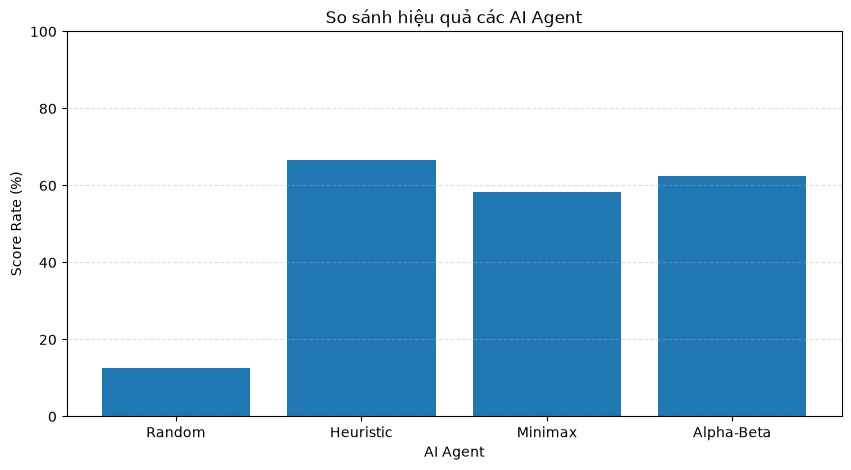

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    df_summary["Agent"],
    df_summary["Score Rate (%)"]
)

plt.title("So sánh hiệu quả các AI Agent")
plt.xlabel("AI Agent")
plt.ylabel("Score Rate (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

In [38]:
df_summary.to_csv(
    "agent_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame(match_results).to_csv(
    "match_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu agent_summary.csv")
print("Đã lưu match_results.csv")

Đã lưu agent_summary.csv
Đã lưu match_results.csv


In [39]:

from agents.mcts_agent import MCTSNode, MCTSAgent

# Khởi tạo MCTS Agent
mcts_agent = MCTSAgent(
    simulations=1000,
    exploration=2 ** 0.5,
    seed=42
)

print("Agent:", mcts_agent.name)
print("Simulations:", mcts_agent.simulations)
print("Exploration:", mcts_agent.exploration)

# Kiểm tra UCT
root = MCTSNode(
    board=[[0, 0], [0, 0]],
    player_to_move=1,
    visits=10
)

child = MCTSNode(
    board=[[1, 0], [0, 0]],
    player_to_move=-1,
    parent=root,
    visits=5,
    wins=4,
    player_just_moved=1
)

root.children.append(child)

print("UCT value:", child.uct_value())

# Kiểm tra sinh nước đi
board = [
    [1, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0]
]

actions = mcts_agent.get_legal_actions(board)

print("Legal actions:", len(actions))

assert len(actions) == 15
assert child.uct_value() > 0

print("\nPASS: MCTS components initialized!")


Agent: MCTS Agent
Simulations: 1000
Exploration: 1.4142135623730951
UCT value: 1.7597051824376164
Legal actions: 15

PASS: MCTS components initialized!


In [40]:
import importlib
import agents.mcts_agent as mcts_module

importlib.reload(mcts_module)

from agents.mcts_agent import MCTSAgent

mcts_agent = MCTSAgent(
    simulations=1000,
    exploration=2 ** 0.5,
    seed=42
)

print("MCTS Agent initialized!")

MCTS Agent initialized!


In [41]:
from game.game_engine import GameEngine

game = GameEngine()

action = mcts_agent.choose_action(game)

print("MCTS action:", action)
print("Nodes visited:", mcts_agent.nodes_visited)

assert action in game.legal_actions()

print("PASS: MCTS selected a legal action!")

MCTS action: (0, 0)
Nodes visited: 1001
PASS: MCTS selected a legal action!


In [42]:
# TEST 1: X có thể thắng ngay
game = GameEngine()

game.state.board[0] = [1, 1, 1, 0]
game.state.current_player = 1

mcts_agent = MCTSAgent(
    simulations=5000,
    seed=42
)

action = mcts_agent.choose_action(game)

print("Winning test:", action)

# TEST 2: X phải chặn O
game = GameEngine()

game.state.board[0] = [-1, -1, -1, 0]
game.state.current_player = 1

action = mcts_agent.choose_action(game)

print("Blocking test:", action)

Winning test: (0, 3)
Blocking test: (0, 3)
